# CPIT: decision, data and provenance

**Question:** How do precedence and capacities turn a value ranking into a period-by-period CPIT schedule?

**Level**: 1

**Prerequisites**: none

**Reading time**: 18 minutes

## Objectives

Define the CPIT decision, trace committed cases, and construct a first schedule with the package. By the end, distinguish a pit from a production sequence and explain the limits of aggregate evidence.

## Setup

From the repository root, install the pinned environment with these versions. The cell reports the versions actually imported.

```bash
pip install oreblocks==0.6.3 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the API and verify versions.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

PhaseFlow maintains the deterministic generator and instance builder; its code is MIT-licensed. The case declares a vein, seed 31, dimensions 4×4×3, four periods, and capacities; it is not field data. twin-porphyry-s is a separate derived manifest. Newman1 is a MineLib aggregate; its block files have academic-download terms and are not redistributed.

Per-file provenance: the committed aggregates are data/derived/manifests/newman1-published.json and data/derived/manifests/twin-porphyry-s.json. MineLib publishes its record at https://minelib.org/v1/Results.xhtml; MineLib owns the benchmark, and its source files carry academic-download terms. PhaseFlow owns the synthetic generator at https://github.com/fsantibanezleal/CAOS_PhaseFlow under the MIT license; its implementation is data-pipeline/pipeline/model/instances.py. The seed and scenario for this example are explicit in code.

In [2]:
# Build the instance through the pipeline and read committed aggregates.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contract accepted:',instance.report.ok,'| blocks:',instance.n_blocks)
print('committed cases:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contract accepted: True | blocks: 48
committed cases: newman1-published twin-porphyry-s


## Method

Cumulative extraction x(i,t) respects precedence x(i,t) ≤ x(j,t). Period extraction is x(i,t) − x(i,t−1), whose value is discounted. Chicoisne et al. (2012), https://doi.org/10.1287/opre.1120.1050, ground the parametric maximum-closure relaxation. This notebook uses the pipeline and OreBlocks rather than copying an implementation. We first compute resource bounds, then schedule, then validate.

An ultimate pit and a production schedule answer different questions. The pit asks which blocks may be extracted together while respecting slope precedence. CPIT adds time: each block is assigned to a period or left unmined, and mining and processing capacities constrain every period. A high-value block can be delayed by prerequisites, a competing resource limit, or discounting. The PhaseFlow pipeline and OreBlocks implement these coupled decisions; merely sorting values omits the central constraint.

For cumulative extraction x(i,t), a precedence arc from prerequisite j to block i imposes x(i,t) <= x(j,t). The period decision is x(i,t)-x(i,t-1), and the objective discounts its value. This notation explains the model, but this notebook does not reimplement it. PhaseFlow builds the declared case and the pinned OreBlocks package schedules it. Chicoisne et al. (2012), DOI 10.1287/opre.1120.1050, derive the single-resource relaxation using nested maximum closures. That result motivates a bound; it does not make a heuristic schedule an exact integer solution.

Input semantics are part of the computation. The product's instance builder constructs values, precedence, resource coefficients and destination alternatives from the deposit and scenario, then runs PhaseFlow's contract checks. Dimensional, capacity and precedence failures must be resolved before trusting a solver result. This lesson uses a deterministic vein twin, seed 31, dimensions 4 by 4 by 3, and four periods. That small scale exposes intermediate values; it does not estimate an operating mine or reproduce a published benchmark.

MineLib Newman1 appears as aggregate evidence only. Its committed manifest records the scenario and results, while the raw block files remain subject to MineLib's academic-download terms and are not redistributed. The manifest can show what PhaseFlow recorded for that case; it cannot reconstruct unavailable block data or independently reproduce the solve. The synthetic lesson is a different case. Keeping the evidence separate prevents the notebook from borrowing benchmark authority it does not possess.

Expected-value TopoSort considers blocks eligible under precedence and applies the package's weight when choosing what to schedule. Its returned period assignments, NPV and bound are useful intermediate results. Unmined blocks use a negative period sentinel. We will summarize assignments by period rather than print an opaque vector, then compare extracted tonnes with capacity. The figure makes resource pressure visible but does not display precedence arcs and cannot replace package validation.

Controls examine independent properties: the feasible value must not exceed its upper bound, the duality construction must agree within tolerance, and input order must not materially change the result. Passing these controls supports confidence in internal computational consistency. It does not validate geological assumptions, prove global integer optimality, or establish runtime at production scale. The lesson's conclusion is deliberately limited to this declared seed and scenario.


Step 1. Compute each resource bound separately to find the tightest certificate.

In [3]:
# Compute bounds using OreBlocks critical multipliers.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
for item in relaxations:
    print('resource',item.resource,'bound',round(item.bound,2),'closures',item.closure_solves)

resource 0 bound 333680.0 closures 31
resource 1 bound 284685.82 closures 57


Step 2. Build an Expected schedule that preserves precedence eligibility.

In [4]:
# Run Expected and report its computed schedule metrics.
schedule, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print('method:', schedule.method)
print('NPV:', round(schedule.npv, 2))
print('upper bound:', round(schedule.bound, 2))
print('mined blocks:', schedule.mined_blocks)

method: toposort:expected[r1]
NPV: 179191.57
upper bound: 284685.82
mined blocks: 16


Step 3. Validate bound direction, duality, and order invariance.

In [5]:
# Apply the package's independent controls.
controls=ob.run_controls(instance.cpit,instance.precedence,schedule)
print(controls.__dict__)

{'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


The chart shows tonnes per period against declared capacity. It helps locate mining pressure, but does not draw precedence or replace controls on the complete schedule.

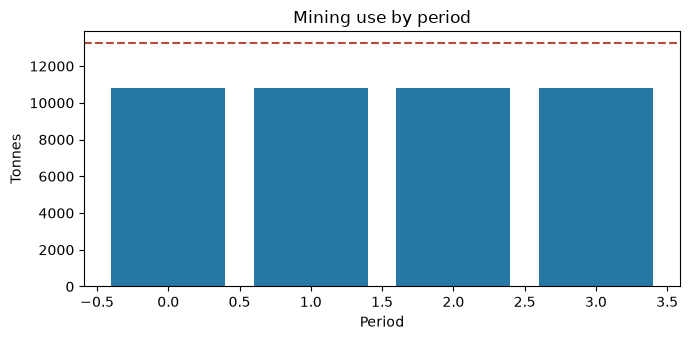

In [6]:
# Plot extraction by period and capacity limit.
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(np.arange(instance.cpit.n_periods),schedule.per_period_resource[0],color='#2878a5')
ax.axhline(instance.cpit.limit[0,0],color='#b64b3b',linestyle='--')
ax.set(
    title='Mining use by period',
    xlabel='Period', ylabel='Tonnes',
)
fig.tight_layout()
plt.show()

## Results

**Answer:** Expected produced an NPV of 179191.57 from 16 mined blocks; its upper bound is 284685.82 and the measured gap is 37.056%. The figure compares tonnes per period with capacity. This is a synthetic teaching case, not MineLib evidence or a proof of optimality.

In [7]:
# Report the computed answer and gap.
print('NPV',round(schedule.npv,2),'| mined blocks',schedule.mined_blocks)
print('bound',round(schedule.bound,2),'| gap %',round(100*(schedule.bound-schedule.npv)/schedule.bound,3))

NPV 179191.57 | mined blocks 16
bound 284685.82 | gap % 37.056


## Summary

The pipeline traces provenance and validates the contract; OreBlocks produces the plan and its controls check computational consistency. The result is heuristic and limited to the declared capacities and economics.

## References

- Chicoisne et al. (2012): https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020): https://doi.org/10.1287/opre.2019.1965
- MineLib Newman1 aggregate: https://minelib.org/v1/Results.xhtml
- PhaseFlow dossiers: docs/methodologies/02_the-bound.md; docs/cases/01_newman1-published.md; docs/cases/04_twin-porphyry-s.md
- PhaseFlow source repository and synthetic-twin generator: https://github.com/fsantibanezleal/CAOS_PhaseFlow